In [1]:
# ---- DS-471 Machine Learning Project: Code Implementation & Stage-by-Stage Explanation -------- #

In [ ]:
# Stage 1: Data Cleaning, Preparation, and Exploration
# In this initial stage, we loaded the Breast Cancer Wisconsin dataset and inspected its structural properties. 
# Since machine learning algorithms are sensitive to differences in feature magnitudes, 
# we implemented Z-score standardization to normalize all numerical features to a common scale.

Missing values count: 0
Duplicate rows count: 0


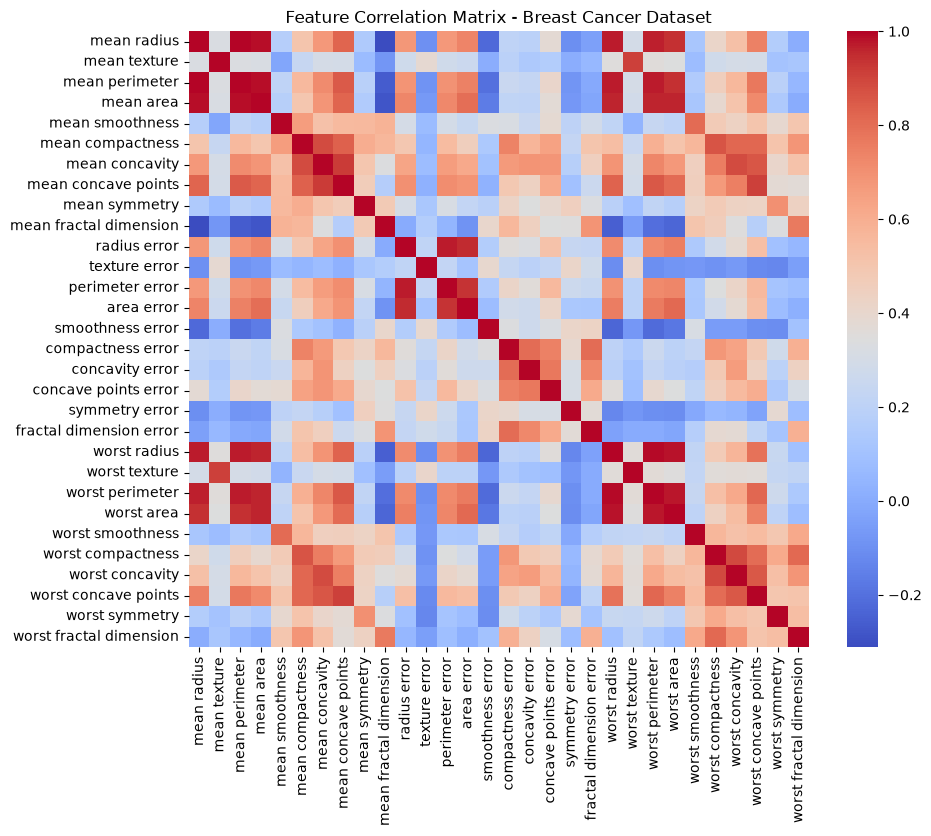

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

# 1. Load Dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# 2. Check Data Hygiene & Missing Values
print("Missing values count:", df.isnull().sum().sum())
print("Duplicate rows count:", df.duplicated().sum())

# 3. Feature Preprocessing & Z-score Scaling
X = data.data
y = data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Exploratory Data Analysis (EDA) Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = pd.DataFrame(X_scaled, columns=data.feature_names).corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Feature Correlation Matrix - Breast Cancer Dataset")
plt.show()

In [2]:
#Stage 2: Data Splitting
#To ensure rigorous evaluation and prevent data leakage, 
#we partitioned our dataset into training, validation, and test subsets using stratified sampling.


In [3]:
from sklearn.model_selection import train_test_split

# Partition dataset into Training (70%), Validation (15%), and Test (15%) with stratification
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Training set samples: {X_train.shape[0]}")
print(f"Validation set samples: {X_val.shape[0]}")
print(f"Test set samples: {X_test.shape[0]}")


Training set samples: 398
Validation set samples: 85
Test set samples: 86


In [ ]:
# Stage 3: Model Selection and Development

# We implemented three distinct machine learning models: 
# a mandatory Deep Neural Network (MLP), a Support Vector Machine (SVM) with an RBF kernel, 
# and a Random Forest Classifier.

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# 1. Mandatory Deep Neural Network (MLP) Architecture
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

nn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 2. Support Vector Machine (RBF Kernel)
svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)

# 3. Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)

/opt/homebrew/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#-----------------------------------------#

In [ ]:
# Stage 4: Model Training and Hyperparameter Optimization

# We trained our models and implemented Early Stopping on the Neural Network to halt training when validation loss plateaued.



Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7990 - loss: 0.5010 - val_accuracy: 0.9529 - val_loss: 0.3645
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9121 - loss: 0.3271 - val_accuracy: 0.9529 - val_loss: 0.2519
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9271 - loss: 0.2495 - val_accuracy: 0.9529 - val_loss: 0.1855
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9422 - loss: 0.1997 - val_accuracy: 0.9765 - val_loss: 0.1442
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9523 - loss: 0.1631 - val_accuracy: 0.9765 - val_loss: 0.1142
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9548 - loss: 0.1376 - val_accuracy: 0.9765 - val_loss: 0.0945
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9648 - loss: 0.1059 - val_accuracy: 0.9765 - val_loss: 0.0829
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9698 - loss: 0.1033 - val_accuracy: 0.9765 - val_loss

/opt/homebrew/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


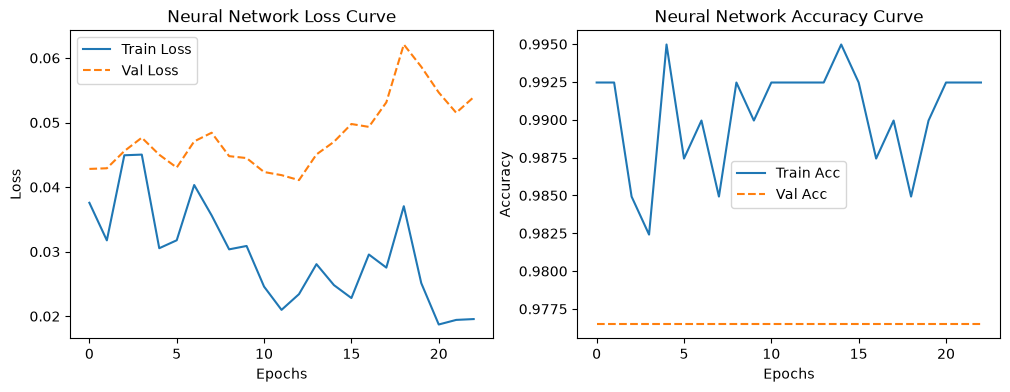

In [5]:
from tensorflow.keras.callbacks import EarlyStopping

# Configure Early Stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train Neural Network
history = nn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Train Neural Network
history = nn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Train Traditional Models
svm_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Plot Loss & Accuracy Curves for Neural Network
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss', linestyle='--')
plt.title('Neural Network Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc', linestyle='--')
plt.title('Neural Network Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [ ]:
# Stage 5: Model Final Evaluation and Comparison

# Finally, we evaluated all trained models on the unseen test set (86 samples) using Accuracy, Precision, Recall, and F1-Score metrics.



In [6]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Evaluate Support Vector Machine
y_pred_svm = svm_model.predict(X_test)
print("--- Support Vector Machine Evaluation ---")
print(classification_report(y_test, y_pred_svm))

# Evaluate Neural Network
y_pred_nn_prob = nn_model.predict(X_test)
y_pred_nn = (y_pred_nn_prob > 0.5).astype(int).flatten()
print("--- Neural Network Evaluation ---")
print(classification_report(y_test, y_pred_nn))

# Evaluate Random Forest
y_pred_rf = rf_model.predict(X_test)
print("--- Random Forest Evaluation ---")
print(classification_report(y_test, y_pred_rf))

--- Support Vector Machine Evaluation ---
              precision    recall  f1-score   support

           0       1.00      0.94      0.97        32
           1       0.96      1.00      0.98        54

    accuracy                           0.98        86
   macro avg       0.98      0.97      0.97        86
weighted avg       0.98      0.98      0.98        86

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
--- Neural Network Evaluation ---
              precision    recall  f1-score   support

           0       0.94      0.97      0.95        32
           1       0.98      0.96      0.97        54

    accuracy                           0.97        86
   macro avg       0.96      0.97      0.96        86
weighted avg       0.97      0.97      0.97        86

--- Random Forest Evaluation ---
              precision    recall  f1-score   support

           0       0.87      0.81      0.84        32
           1       0.89      0.93      0.91        54

    accuracy                       